## **문제 1번: CSV 파일 읽기, 기본 정보 확인**

In [21]:
import pandas as pd

# 1. CSV 파일 읽기
booking_raw = pd.read_csv('hotel_bookings.csv')

# 2. 처음 5개 행과 전체 행 수·열 수 출력
print("=== 처음 5개 행 ===")
display(booking_raw.head())
print(f"\n전체 행 수: {booking_raw.shape[0]}, 전체 열 수: {booking_raw.shape[1]} (shape: {booking_raw.shape})")

# 3. 각 열의 자료형 확인
print("\n=== 각 열의 자료형 확인 ===")
print(booking_raw.dtypes)
print()
booking_raw.info()

# 4. 수치형 열의 기술통계량 출력
print("\n=== 수치형 열 기술통계량 ===")
display(booking_raw.describe())

# 5. 열별 결측치 개수와 결측률(%) 표 출력
missing_cnt = booking_raw.isna().sum()
missing_pct = (booking_raw.isna().mean() * 100).round(2)
missing_df = pd.DataFrame({
    '결측치_개수': missing_cnt,
    '결측률(%)': missing_pct,
    '자료형': booking_raw.dtypes
})
print("\n=== 열별 결측치 현황표 ===")
display(missing_df)

# 6. 취소 예약과 미취소 예약의 건수 및 전체 예약 대비 비율(%) 출력
cancel_cnt = booking_raw['is_canceled'].value_counts().sort_index()
cancel_pct = (booking_raw['is_canceled'].value_counts(normalize=True).sort_index() * 100).round(2)
cancel_df = pd.DataFrame({
    '구분': cancel_cnt.index.map({0: '미취소(0)', 1: '취소(1)'}),
    '예약_건수': cancel_cnt.values,
    '비율(%)': cancel_pct.values
})
print("\n=== 취소/미취소 예약 현황 ===")
display(cancel_df)

=== 처음 5개 행 ===


,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,room_type,daily_rate,booking_channel,is_canceled
0,HB0204,15.0,2.0,5.0,2.0,1.0,Deluxe,180000.0,Direct,0
1,HB0267,7.0,0.0,4.0,2.0,0.0,Standard,130000.0,Direct,0
2,HB0153,28.0,2.0,4.0,1.0,0.0,Standard,70000.0,Online,0
3,HB0010,30.0,2.0,3.0,2.0,2.0,Standard,130000.0,Online,0
4,HB0234,171.0,0.0,4.0,2.0,1.0,Standard,120000.0,Agency,0



전체 행 수: 300, 전체 열 수: 10 (shape: (300, 10))

=== 각 열의 자료형 확인 ===
booking_id          object
lead_time          float64
weekend_nights     float64
weekday_nights     float64
adults             float64
children           float64
room_type           object
daily_rate         float64
booking_channel     object
is_canceled          int64
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   booking_id       300 non-null    object 
 1   lead_time        298 non-null    float64
 2   weekend_nights   298 non-null    float64
 3   weekday_nights   298 non-null    float64
 4   adults           298 non-null    float64
 5   children         298 non-null    float64
 6   room_type        296 non-null    object 
 7   daily_rate       296 non-null    float64
 8   booking_channel  296 non-null    object 
 9   is_canceled      300 non-null    i

,lead_time,weekend_nights,weekday_nights,adults,children,daily_rate,is_canceled
count,298.000000,298.000000,298.000000,298.000000,298.000000,296.000000,300.000000
mean,47.677852,0.942953,2.953020,1.768456,0.422819,166587.837838,0.233333
std,51.739801,0.812425,1.448722,0.605873,0.683438,137061.828387,0.423659
min,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-10000.000000,0.000000
25%,8.000000,0.000000,2.000000,1.000000,0.000000,100000.000000,0.000000
50%,23.000000,1.000000,3.000000,2.000000,0.000000,120000.000000,0.000000
75%,78.750000,2.000000,4.000000,2.000000,1.000000,180000.000000,0.000000
max,179.000000,2.000000,5.000000,3.000000,2.000000,1000000.000000,1.000000



=== 열별 결측치 현황표 ===


,결측치_개수,결측률(%),자료형
booking_id,0,0.00,object
lead_time,2,0.67,float64
weekend_nights,2,0.67,float64
weekday_nights,2,0.67,float64
adults,2,0.67,float64
children,2,0.67,float64
room_type,4,1.33,object
daily_rate,4,1.33,float64
booking_channel,4,1.33,object
is_canceled,0,0.00,int64



=== 취소/미취소 예약 현황 ===


,구분,예약_건수,비율(%)
0,미취소(0),230,76.67
1,취소(1),70,23.33


**[정제가 필요한 항목 두 가지]**
1. **결측치 처리 필요**

  * lead_time, weekend_nights, weekday_nights, adults, children(각 2건)과 room_type, daily_rate, booking_channel(각 4건)에 결측치가 존재
  * 특히 children의 결측치는 '어린이 0명'을 의미하지 않으므로 임의의 0 대체가 아닌 적절한 정제 기준이 필요(전체 데이터에서 children이 0.0인 행이 202건이나 있음)

2. **음수 오류 값 정제 필요**

  * 기술통계량의 min 값을 보면 lead_time, weekend_nights, weekday_nights, adults, children이 -1.0, daily_rate가 -10000.0으로 나타남
  * 예약 선행일수·숙박일수·인원수는 음수가 될 수 없고, 객실 요금(daily_rate)은 0보다 커야 하므로 데이터 오류에 해당

## **문제 2번: 결측치와 명확한 오류 값 처리**

In [22]:
import numpy as np

# 1. booking_raw 복사하여 booking_clean 생성
booking_clean = booking_raw.copy()
rows_before = len(booking_clean)

# 2. 오류 조건에 해당하는 행 탐색 및 예약 번호·오류 값 출력
#    - lead_time, weekend_nights, weekday_nights, adults, children 중 하나라도 음수(< 0)
#    - daily_rate가 0 이하(<= 0)
non_neg_cols = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']
neg_mask = (booking_clean[non_neg_cols] < 0).any(axis=1)
rate_err_mask = booking_clean['daily_rate'] <= 0
error_row_mask = neg_mask | rate_err_mask

print("=== 오류 조건 해당 행(예약 번호 및 오류 값) ===")
error_cols_to_show = ['booking_id'] + non_neg_cols + ['daily_rate']
display(booking_clean.loc[error_row_mask, error_cols_to_show])

# 3. 오류 값이 있는 '셀'만 결측값(np.nan)으로 변경
for col in non_neg_cols:
    booking_clean.loc[booking_clean[col] < 0, col] = np.nan

booking_clean.loc[booking_clean['daily_rate'] <= 0, 'daily_rate'] = np.nan

# 4. 기준에 따른 결측치 처리
# (a) lead_time, weekend_nights, weekday_nights, adults, children 중 하나라도 결측이면 해당 행 제외
drop_subset = ['lead_time', 'weekend_nights', 'weekday_nights', 'adults', 'children']
rows_before_drop = len(booking_clean)
booking_clean = booking_clean.dropna(subset=drop_subset).copy()
rows_dropped = rows_before_drop - len(booking_clean)

# (b) daily_rate 결측치는 오류→NaN 처리 및 행 제외 이후의 유효한 daily_rate 중앙값으로 대체
valid_rate_median = booking_clean['daily_rate'].median()
booking_clean['daily_rate'] = booking_clean['daily_rate'].fillna(valid_rate_median)

# (c) room_type, booking_channel 결측치는 'Unknown'으로 대체
booking_clean['room_type'] = booking_clean['room_type'].fillna('Unknown')
booking_clean['booking_channel'] = booking_clean['booking_channel'].fillna('Unknown')

# 5. 처리 전후 행 수, 제외한 행 수, 남은 결측치 개수 출력
rows_after = len(booking_clean)
print("\n=== 행 수 변화 및 남은 결측치 ===")
print(f"처리 전 행 수: {rows_before}")
print(f"제외한 행 수: {rows_dropped}")
print(f"처리 후 행 수: {rows_after}")
print("\n남은 결측치 개수:")
print(booking_clean.isna().sum())

# 6. 처리 후 음수 일수·인원수와 0 이하 요금 잔존 여부 확인
rem_neg = (booking_clean[non_neg_cols] < 0).sum().to_dict()
rem_nonpos_rate = int((booking_clean['daily_rate'] <= 0).sum())
print("\n=== 오류 값 잔존 검증 ===")
print("음수 일수·인원수 잔존 개수(열별):", rem_neg)
print("0 이하 daily_rate 잔존 개수:", rem_nonpos_rate)

=== 오류 조건 해당 행(예약 번호 및 오류 값) ===


,booking_id,lead_time,weekend_nights,weekday_nights,adults,children,daily_rate
13,HB0046,137.0,2.0,3.0,1.0,0.0,-10000.0
25,HB0043,6.0,2.0,-1.0,3.0,1.0,250000.0
38,HB0047,1.0,1.0,2.0,2.0,0.0,0.0
173,HB0042,27.0,-1.0,1.0,2.0,0.0,190000.0
216,HB0045,74.0,2.0,2.0,2.0,-1.0,160000.0
219,HB0041,-1.0,2.0,3.0,1.0,1.0,180000.0
243,HB0044,29.0,0.0,5.0,-1.0,0.0,130000.0



=== 행 수 변화 및 남은 결측치 ===
처리 전 행 수: 300
제외한 행 수: 15
처리 후 행 수: 285

남은 결측치 개수:
booking_id         0
lead_time          0
weekend_nights     0
weekday_nights     0
adults             0
children           0
room_type          0
daily_rate         0
booking_channel    0
is_canceled        0
dtype: int64

=== 오류 값 잔존 검증 ===
음수 일수·인원수 잔존 개수(열별): {'lead_time': 0, 'weekend_nights': 0, 'weekday_nights': 0, 'adults': 0, 'children': 0}
0 이하 daily_rate 잔존 개수: 0


**[일수·인원수 임의 대체의 영향]**
* 선행일수(lead_time), 숙박일수(weekend_nights, weekday_nights), 인원수(adults, children)를 임의의 값으로 채우면 실제 예약 기간이나 투숙 인원 규모가 왜곡되어 총 숙박일수·총 인원수 집계와 사전 확인 대상 필터링 정확도가 떨어짐.

**[요금 대체값 선택 이유]**
* 객실 요금(daily_rate)은 고가 객실이나 고액 요금 데이터로 인해 분포가 오른쪽으로 치우칠 수 있으므로, 극단값의 영향을 덜 받는 중앙값(120,000.0원)으로 대체하는 것이 대표성을 유지하기에 적절함.

**['Unknown' 사용 이유]**
* room_type과 booking_channel의 결측치를 임의로 특정 유형·경로로 채우면 해당 집단의 건수와 취소율이 왜곡되므로, 누락 사실을 명시적으로 보존하는 'Unknown' 범주로 분리함.

## **문제 3번: 객실 요금의 이상치 후보 탐지 및 처리**

=== 분위수 및 이상치 경계값 ===
Q1 (25%): 100,000원
Q3 (75%): 180,000원
IQR: 80,000원
하한: -20,000원 (하한 미만은 음수이므로 해당 없음)
상한: 300,000원

=== 이상치 후보 현황 ===
이상치 후보 건수: 26건
전체 대비 비율: 9.12%

=== 이상치 후보 목록 (총 26건) ===


,booking_id,room_type,daily_rate
7,HB0110,Suite,550000.0
8,HB0006,Suite,450000.0
14,HB0183,Suite,350000.0
32,HB0034,Suite,640000.0
37,HB0091,Suite,800000.0
57,HB0093,Suite,1000000.0
67,HB0257,Suite,420000.0
81,HB0155,Suite,560000.0
85,HB0115,Suite,480000.0
98,HB0275,Suite,580000.0



=== 요금 요약 통계량 비교 ===


,구분,원래 요금(daily_rate),처리된 요금(daily_rate_processed)
0,최솟값,70000.0,70000.0
1,중앙값,120000.0,120000.0
2,최댓값,1000000.0,1000000.0


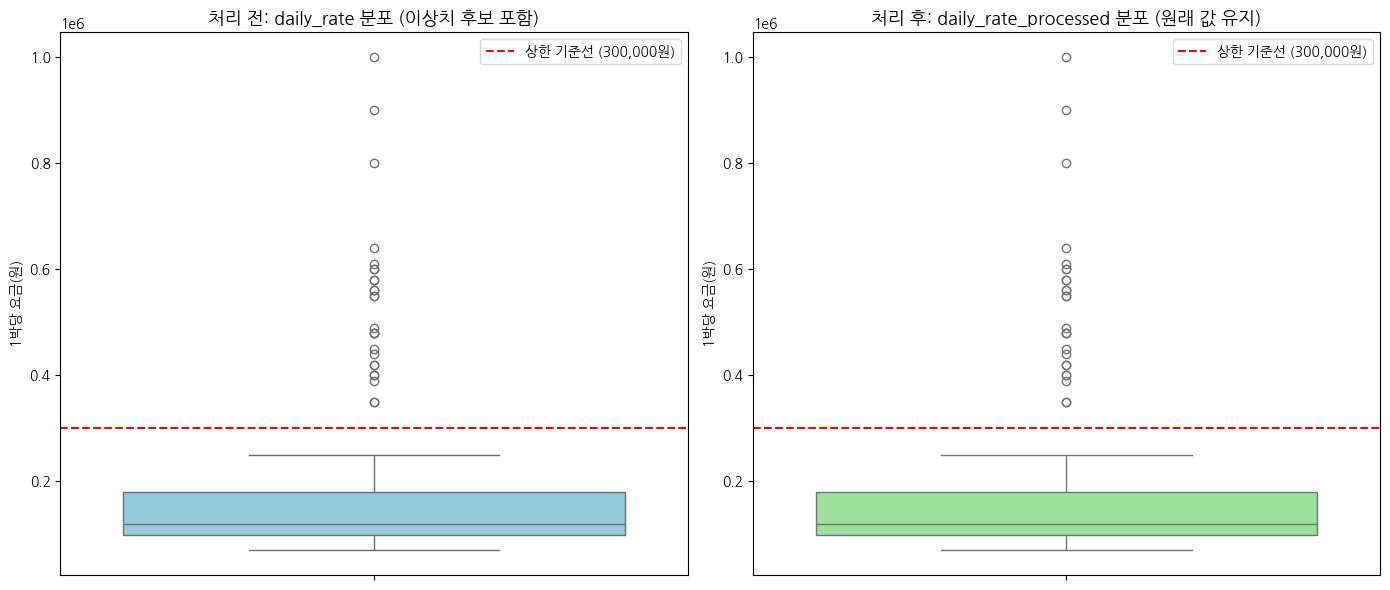

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Colab 환경)
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

# 1. 문제 2에서 정제한 booking_clean 사용 (기본 확인)
# 2. daily_rate의 Q1, Q3, IQR 계산
Q1 = booking_clean['daily_rate'].quantile(0.25)
Q3 = booking_clean['daily_rate'].quantile(0.75)
IQR = Q3 - Q1

# 3. 하한(Lower bound) 및 상한(Upper bound) 계산
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"=== 분위수 및 이상치 경계값 ===")
print(f"Q1 (25%): {Q1:,.0f}원")
print(f"Q3 (75%): {Q3:,.0f}원")
print(f"IQR: {IQR:,.0f}원")
print(f"하한: {lower_bound:,.0f}원 (하한 미만은 음수이므로 해당 없음)")
print(f"상한: {upper_bound:,.0f}원")

# 4. 하한보다 작거나 상한보다 큰 이상치 후보 탐지
outliers = booking_clean[(booking_clean['daily_rate'] < lower_bound) | (booking_clean['daily_rate'] > upper_bound)]

# 5. 이상치 후보 건수와 비율(%) 출력
outlier_count = len(outliers)
outlier_ratio = (outlier_count / len(booking_clean)) * 100
print(f"\n=== 이상치 후보 현황 ===")
print(f"이상치 후보 건수: {outlier_count}건")
print(f"전체 대비 비율: {outlier_ratio:.2f}%")

# 6. 해당 예약의 booking_id, room_type, daily_rate 출력
print(f"\n=== 이상치 후보 목록 (총 {outlier_count}건) ===")
display(outliers[['booking_id', 'room_type', 'daily_rate']])

# 7. 처리 방법 선택 및 daily_rate_processed 생성
# -> '원래 값 유지' 선택: 스위트룸 등 정상적인 고가 예약이므로 실제 요금을 보존함
# (참고: 과제 제출 유의사항에 따라 원본 daily_rate는 보존함)
booking_clean['daily_rate_processed'] = booking_clean['daily_rate']

# 8. 원래 요금과 처리된 요금의 최솟값·중앙값·최댓값 비교
summary_comp = pd.DataFrame({
    '구분': ['최솟값', '중앙값', '최댓값'],
    '원래 요금(daily_rate)': [
        booking_clean['daily_rate'].min(),
        booking_clean['daily_rate'].median(),
        booking_clean['daily_rate'].max()
    ],
    '처리된 요금(daily_rate_processed)': [
        booking_clean['daily_rate_processed'].min(),
        booking_clean['daily_rate_processed'].median(),
        booking_clean['daily_rate_processed'].max()
    ]
})
print("\n=== 요금 요약 통계량 비교 ===")
display(summary_comp)

# 9. 처리 전후 박스플롯 작성
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.boxplot(y=booking_clean['daily_rate'], ax=axes[0], color='skyblue')
axes[0].set_title('처리 전: daily_rate 분포 (이상치 후보 포함)', fontsize=13)
axes[0].set_ylabel('1박당 요금(원)')
axes[0].axhline(upper_bound, color='red', linestyle='--', label=f'상한 기준선 ({upper_bound:,.0f}원)')
axes[0].legend()

sns.boxplot(y=booking_clean['daily_rate_processed'], ax=axes[1], color='lightgreen')
axes[1].set_title('처리 후: daily_rate_processed 분포 (원래 값 유지)', fontsize=13)
axes[1].set_ylabel('1박당 요금(원)')
axes[1].axhline(upper_bound, color='red', linestyle='--', label=f'상한 기준선 ({upper_bound:,.0f}원)')
axes[1].legend()

plt.tight_layout()
plt.show()

**[처리 방법의 근거]**
* 상한(300,000원)을 초과한 26건의 이상치 후보를 객실 유형별로 분석한 결과, 25건이 고가 객실인 Suite(스위트룸) 예약이며 나머지 1건은 Unknown임
* 발제 조건에 명시된 대로 "객실 유형에 따라 요금이 다르므로 높은 요금이 반드시 오류는 아니다"라는 도메인 규칙이 성립하며, 스위트룸의 실제 시장 가격대를 감안할 때 정상적인 고가 예약으로 판단할 수 있음
* 따라서 데이터를 강제로 상한값으로 깎아내리기보다는 실제 결제/예약 금액을 보존하는 '원래 값 유지'가 비즈니스 관점에서 가장 타당함

**[IQR 범위 이탈에 대한 오류 판정]**
* IQR 범위 이탈만으로 입력 오류라고 판단할 수 없음
* IQR 방식은 단일 변수의 통계적 분포상 상위 꼬리 부분에 위치한 극단값을 식별하는 기법일 뿐임
* Standard, Deluxe, Suite 등 호텔 객실처럼 가격 체계가 다변화된 경우, IQR 범위를 이탈하더라도 정상값일 수 있음 (고가의 객실)
* 따라서 IQR 이탈값은 오류가 아닌 추가 확인 대상으로 보아야 함

## **문제 4번: 업무에 필요한 파생변수 생성**

In [24]:
# 1. 네 가지 파생변수 생성
booking_clean['total_nights'] = booking_clean['weekend_nights'] + booking_clean['weekday_nights']
booking_clean['total_guests'] = booking_clean['adults'] + booking_clean['children']
booking_clean['estimated_room_amount'] = booking_clean['daily_rate'] * booking_clean['total_nights']

# lead_time_group 구간 생성 (0~7일: Within7Days, 7일 초과~30일 이하: 8to30Days, 30일 초과: Over30Days)
conditions = [
    (booking_clean['lead_time'] >= 0) & (booking_clean['lead_time'] <= 7),
    (booking_clean['lead_time'] > 7) & (booking_clean['lead_time'] <= 30),
    (booking_clean['lead_time'] > 30)
]
choices = ['Within7Days', '8to30Days', 'Over30Days']
booking_clean['lead_time_group'] = np.select(conditions, choices, default='Unknown')

# 2. total_nights가 0이거나 total_guests가 0인 예약 번호와 건수 출력
zero_mask = (booking_clean['total_nights'] == 0) | (booking_clean['total_guests'] == 0)
zero_rows = booking_clean.loc[
    zero_mask,
    ['booking_id', 'weekend_nights', 'weekday_nights', 'total_nights', 'adults', 'children', 'total_guests']
]

print("=== total_nights == 0 또는 total_guests == 0인 예약 ===")
print(f"해당 예약 건수: {len(zero_rows)}건")
display(zero_rows)

# 3. 숙박과 투숙 인원이 없는 예약 제외
rows_before_p4 = len(booking_clean)
booking_clean = booking_clean.loc[~zero_mask].copy()
rows_after_p4 = len(booking_clean)

# 4. 최종 행 수와 주요 열의 처음 10개 행 출력
key_cols = [
    'booking_id', 'lead_time', 'lead_time_group',
    'total_nights', 'total_guests', 'room_type',
    'daily_rate', 'estimated_room_amount', 'booking_channel', 'is_canceled'
]
print(f"\n=== 제외 전 행 수: {rows_before_p4} -> 최종 행 수: {rows_after_p4} ===")
display(booking_clean[key_cols].head(10))

# 5. lead_time이 7일일 때와 30일일 때 각각 올바른 구간에 포함되는지 확인
print("\n=== lead_time 7일 및 30일 경계 검증 ===")
print("lead_time == 7 구간 분포 (Within7Days 예상):",
      booking_clean[booking_clean['lead_time'] == 7]['lead_time_group'].value_counts().to_dict())
print("lead_time == 30 구간 분포 (8to30Days 예상):",
      booking_clean[booking_clean['lead_time'] == 30]['lead_time_group'].value_counts().to_dict())

display(
    booking_clean[booking_clean['lead_time'].isin([7, 30])][['booking_id', 'lead_time', 'lead_time_group']].head(10)
)

=== total_nights == 0 또는 total_guests == 0인 예약 ===
해당 예약 건수: 4건


,booking_id,weekend_nights,weekday_nights,total_nights,adults,children,total_guests
169,HB0052,0.0,0.0,0.0,3.0,0.0,3.0
251,HB0054,1.0,3.0,4.0,0.0,0.0,0.0
261,HB0053,2.0,1.0,3.0,0.0,0.0,0.0
271,HB0051,0.0,0.0,0.0,2.0,0.0,2.0



=== 제외 전 행 수: 285 -> 최종 행 수: 281 ===


,booking_id,lead_time,lead_time_group,total_nights,total_guests,room_type,daily_rate,estimated_room_amount,booking_channel,is_canceled
0,HB0204,15.0,8to30Days,7.0,3.0,Deluxe,180000.0,1260000.0,Direct,0
1,HB0267,7.0,Within7Days,4.0,2.0,Standard,130000.0,520000.0,Direct,0
2,HB0153,28.0,8to30Days,6.0,1.0,Standard,70000.0,420000.0,Online,0
3,HB0010,30.0,8to30Days,5.0,4.0,Standard,130000.0,650000.0,Online,0
4,HB0234,171.0,Over30Days,4.0,3.0,Standard,120000.0,480000.0,Agency,0
5,HB0227,143.0,Over30Days,5.0,4.0,Standard,100000.0,500000.0,Direct,0
6,HB0197,91.0,Over30Days,3.0,2.0,Deluxe,160000.0,480000.0,Online,1
7,HB0110,27.0,8to30Days,3.0,1.0,Suite,550000.0,1650000.0,Agency,0
8,HB0006,6.0,Within7Days,4.0,2.0,Suite,450000.0,1800000.0,Direct,1
9,HB0176,127.0,Over30Days,2.0,3.0,Standard,80000.0,160000.0,Direct,1



=== lead_time 7일 및 30일 경계 검증 ===
lead_time == 7 구간 분포 (Within7Days 예상): {'Within7Days': 6}
lead_time == 30 구간 분포 (8to30Days 예상): {'8to30Days': 5}


,booking_id,lead_time,lead_time_group
1,HB0267,7.0,Within7Days
3,HB0010,30.0,8to30Days
32,HB0034,7.0,Within7Days
42,HB0287,7.0,Within7Days
45,HB0064,30.0,8to30Days
91,HB0102,30.0,8to30Days
121,HB0173,30.0,8to30Days
164,HB0029,7.0,Within7Days
190,HB0062,7.0,Within7Days
283,HB0277,7.0,Within7Days


**[파생변수의 운영팀 활용 방안]**
1. **total_nights**: 총 숙박 기간을 파악해 객실 회전율, 청소·운영 스케줄 및 장기/단기 투숙 패턴을 관리하는 데 활용 가능
2. **total_guests**: 예약별 총 투숙 인원을 집계해 어메니티·조식 준비량 산정과 객실 수용 인원 적합성을 점검하는 데 활용 가능
3. **estimated_room_amount**: 예약 기준 예상 객실 금액 규모를 산출해 사전 확인이 필요한 고액 예약 우선순위를 정하고 객실 매출 흐름을 가늠하는 데 활용 가능
4. **lead_time_group**: 입실 임박도(7일 이내, 8~30일, 30일 초과)별로 예약을 묶어 직전 취소 위험이 큰 단기 선행 예약에 대한 사전 안내 및 오버부킹 대응 전략을 수립하는 데 활용 가능

**[estimated_room_amount를 실제 매출이라고 부를 수 없는 이유]**
* 예상 객실 금액은 기준 시점의 예약 단가(daily_rate)와 총 숙박일수(total_nights)를 곱한 단순 추정치일 뿐, 실제 취소·노쇼·환불·프로모션 할인이나 부대/추가 요금 정산 결과가 반영되어 있지 않으며 미취소 예약 역시 최종 투숙 완료를 뜻하지 않기 때문임

## **문제 5번: 사전 확인 대상 예약 추출**

In [25]:
# 1. 네 가지 조건을 모두 만족하는 예약 추출하여 selected에 저장
# 조건 1: 아직 취소되지 않은 예약 (is_canceled == 0)
# 조건 2: 예정 입실일보다 60일 이상 전에 접수된 예약 (lead_time >= 60)
# 조건 3: 총 숙박일수가 3일 이상인 예약 (total_nights >= 3)
# 조건 4: 예약 경로가 Online 또는 Agency인 예약 (booking_channel.isin(['Online', 'Agency']))
cond_not_canceled = (booking_clean['is_canceled'] == 0)
cond_lead_time = (booking_clean['lead_time'] >= 60)
cond_nights = (booking_clean['total_nights'] >= 3)
cond_channel = booking_clean['booking_channel'].isin(['Online', 'Agency'])

selected = booking_clean[cond_not_canceled & cond_lead_time & cond_nights & cond_channel].copy()

# 2. 지정된 열 정의
target_cols = [
    "booking_id",
    "booking_channel",
    "lead_time",
    "total_nights",
    "total_guests",
    "estimated_room_amount"
]

# 3. 예상 객실 요금이 큰 순서대로 정렬하여 처음 10개 행 출력
selected_sorted = selected.sort_values(by="estimated_room_amount", ascending=False)
print("=== 예상 객실 요금 내림차순 상위 10개 행 ===")
display(selected_sorted[target_cols].head(10))

# 4. 사전 확인 대상 예약의 전체 건수와 예상 객실 요금 합계 출력
total_count = len(selected)
total_amount = selected['estimated_room_amount'].sum()

print("\n=== 사전 확인 대상 규모 및 예상 요금 합계 ===")
print(f"사전 확인 대상 전체 건수: {total_count}건")
print(f"예상 객실 요금 합계: {total_amount:,.0f}원")

# 5. 추출된 데이터가 네 가지 조건을 모두 만족하는지 코드로 확인 (.all() 사용)
check_not_canceled = (selected['is_canceled'] == 0).all()
check_lead_time = (selected['lead_time'] >= 60).all()
check_nights = (selected['total_nights'] >= 3).all()
check_channel = selected['booking_channel'].isin(['Online', 'Agency']).all()

print("\n=== 조건 만족 여부 검증 (모두 True여야 함) ===")
print(f"1) 미취소 여부 검증 (is_canceled == 0): {check_not_canceled}")
print(f"2) 선행일수 60일 이상 검증 (lead_time >= 60): {check_lead_time} (최솟값: {selected['lead_time'].min()})")
print(f"3) 총 숙박일수 3일 이상 검증 (total_nights >= 3): {check_nights} (최솟값: {selected['total_nights'].min()})")
print(f"4) 예약 경로 검증 (Online, Agency): {check_channel} (실제 포함 경로: {list(selected['booking_channel'].unique())})")

=== 예상 객실 요금 내림차순 상위 10개 행 ===


,booking_id,booking_channel,lead_time,total_nights,total_guests,estimated_room_amount
198,HB0028,Online,154.0,4.0,2.0,1920000.0
149,HB0084,Online,157.0,6.0,3.0,1440000.0
50,HB0181,Agency,79.0,7.0,2.0,1260000.0
292,HB0122,Online,133.0,4.0,2.0,1000000.0
52,HB0240,Online,115.0,7.0,1.0,910000.0
78,HB0067,Online,60.0,5.0,2.0,900000.0
232,HB0292,Online,154.0,5.0,4.0,900000.0
93,HB0225,Agency,84.0,7.0,2.0,840000.0
41,HB0077,Agency,150.0,3.0,2.0,750000.0
140,HB0116,Online,92.0,4.0,2.0,720000.0



=== 사전 확인 대상 규모 및 예상 요금 합계 ===
사전 확인 대상 전체 건수: 35건
예상 객실 요금 합계: 21,510,000원

=== 조건 만족 여부 검증 (모두 True여야 함) ===
1) 미취소 여부 검증 (is_canceled == 0): True
2) 선행일수 60일 이상 검증 (lead_time >= 60): True (최솟값: 60.0)
3) 총 숙박일수 3일 이상 검증 (total_nights >= 3): True (최솟값: 3.0)
4) 예약 경로 검증 (Online, Agency): True (실제 포함 경로: ['Agency', 'Online'])


## **문제 6번: 예약 현황과 취소 비율 시각화**

=== 예약 경로별 예약·취소 현황 ===


,booking_channel,전체예약건수,취소건수,취소율(%)
0,Agency,53,9,16.98
1,Direct,83,13,15.66
2,Online,141,42,29.79
3,Unknown,4,1,25.00



=== 선행일수 구간별 예약·취소 현황 ===


,lead_time_group,전체예약건수,취소건수,취소율(%)
0,Within7Days,69,12,17.39
1,8to30Days,100,13,13.00
2,Over30Days,112,40,35.71


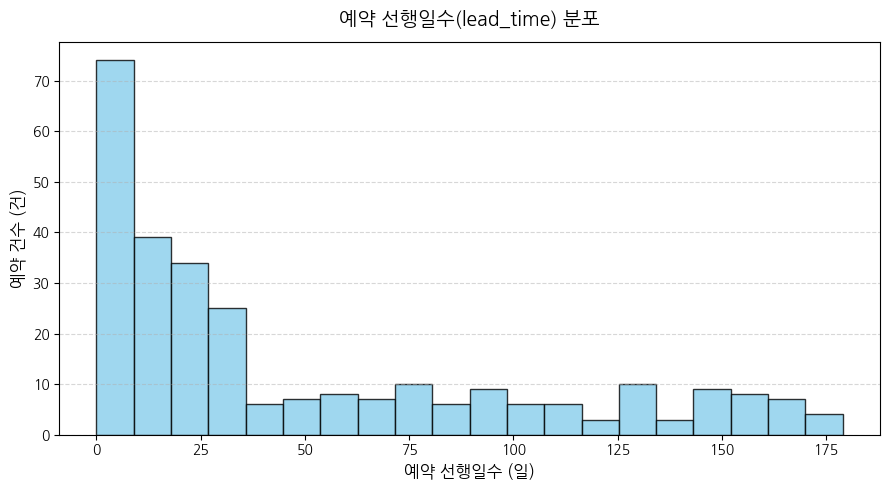

/tmp/ipykernel_612/333502949.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax2 = sns.barplot(data=ch_summary, x='booking_channel', y='취소율(%)', palette='Blues_d')


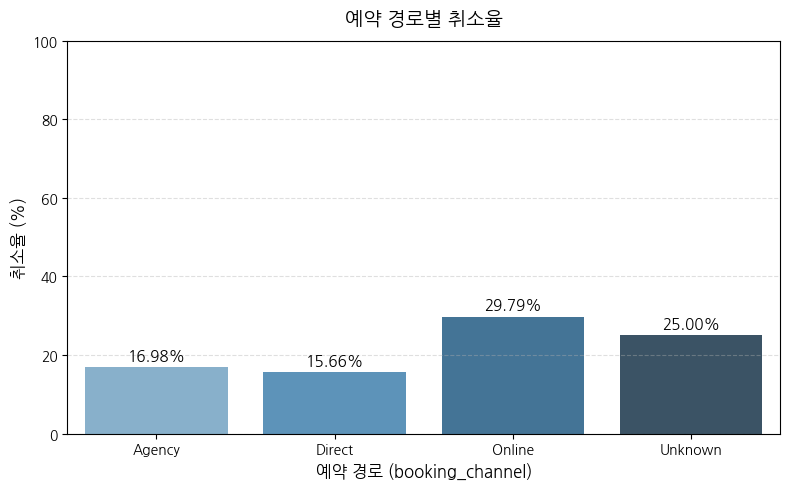

/tmp/ipykernel_612/333502949.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax3 = sns.barplot(data=lt_summary, x='lead_time_group', y='취소율(%)', order=lt_order, palette='Oranges_d')


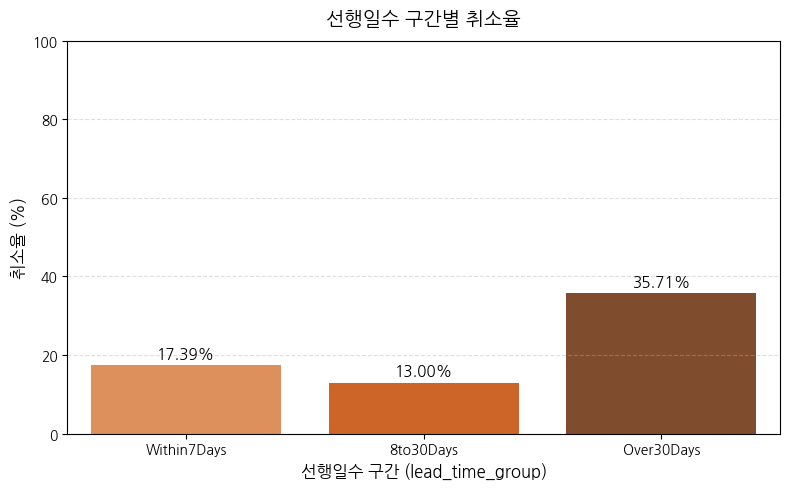

In [26]:
# 한글 폰트 설정 (Colab 환경)
!pip install -q koreanize-matplotlib
import koreanize_matplotlib

# -------------------------------------------------------------
# 1. 취소율 차트 작성 전 집단별 예약 건수·취소 건수·취소율 표 출력
# -------------------------------------------------------------
# (1) 예약 경로(booking_channel)별 집계
ch_summary = booking_clean.groupby('booking_channel')['is_canceled'].agg(
    전체예약건수='count',
    취소건수='sum'
).reset_index()
ch_summary['취소율(%)'] = (ch_summary['취소건수'] / ch_summary['전체예약건수'] * 100).round(2)

print("=== 예약 경로별 예약·취소 현황 ===")
display(ch_summary)

# (2) 선행일수 구간(lead_time_group)별 집계 (지정 순서 적용)
lt_order = ['Within7Days', '8to30Days', 'Over30Days']
lt_summary = booking_clean.groupby('lead_time_group')['is_canceled'].agg(
    전체예약건수='count',
    취소건수='sum'
).reindex(lt_order).reset_index()
lt_summary['취소율(%)'] = (lt_summary['취소건수'] / lt_summary['전체예약건수'] * 100).round(2)

print("\n=== 선행일수 구간별 예약·취소 현황 ===")
display(lt_summary)

# -------------------------------------------------------------
# 2. 세 가지 차트 작성 (Matplotlib + Seaborn 혼용)
# -------------------------------------------------------------

# [차트 1] lead_time의 분포 (Matplotlib 히스토그램)
plt.figure(figsize=(9, 5))
plt.hist(booking_clean['lead_time'], bins=20, color='skyblue', edgecolor='black', alpha=0.8)
plt.title('예약 선행일수(lead_time) 분포', fontsize=14, pad=12)
plt.xlabel('예약 선행일수 (일)', fontsize=12)
plt.ylabel('예약 건수 (건)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# [차트 2] booking_channel 별 취소율 (Seaborn 막대그래프)
plt.figure(figsize=(8, 5))
ax2 = sns.barplot(data=ch_summary, x='booking_channel', y='취소율(%)', palette='Blues_d')
plt.title('예약 경로별 취소율', fontsize=14, pad=12)
plt.xlabel('예약 경로 (booking_channel)', fontsize=12)
plt.ylabel('취소율 (%)', fontsize=12)
plt.ylim(0, 100)  # Y축 0~100% 설정

# 막대 상단 취소율 숫자 표시
for p in ax2.patches:
    height = p.get_height()
    ax2.annotate(f'{height:.2f}%',
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=11, xytext=(0, 3),
                 textcoords='offset points')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# [차트 3] lead_time_group 별 취소율 (Seaborn 막대그래프, 순서 고정)
plt.figure(figsize=(8, 5))
ax3 = sns.barplot(data=lt_summary, x='lead_time_group', y='취소율(%)', order=lt_order, palette='Oranges_d')
plt.title('선행일수 구간별 취소율', fontsize=14, pad=12)
plt.xlabel('선행일수 구간 (lead_time_group)', fontsize=12)
plt.ylabel('취소율 (%)', fontsize=12)
plt.ylim(0, 100)  # Y축 0~100% 설정

# 막대 상단 취소율 숫자 표시
for p in ax3.patches:
    height = p.get_height()
    ax3.annotate(f'{height:.2f}%',
                 (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=11, xytext=(0, 3),
                 textcoords='offset points')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

**[차트별 해석]**

1. **차트 1**
* 예약 선행일수는 0~30일 구간(중앙값 24일)에 집중적으로 밀집되어 있으며, 30일을 초과하는 장기 선행 예약은 일수가 길어질수록 점차 완만하게 감소하는 오른쪽 꼬리가 긴 형태를 보임
2. **차트 2**
* 전체 예약의 과반을 차지하는 Online 경로의 취소율이 29.79%로 Direct(15.66%)나 Agency(16.98%)보다 높게 관측되었으나, 단 4건에 불과한 Unknown(25.00%) 집단은 표본 수가 매우 적어 해석에 유의해야 함
3. **차트 3**
* 입실 30일 이전에 접수된 Over30Days 구간의 취소율이 35.71%로 Within7Days(17.39%)나 8to30Days(13.00%)에 비해 2배 이상 높게 나타나, 장기 예약일수록 일정 변경에 따른 취소 비중이 상대적으로 큼

## **문제 7번: 예약 운영팀에 분석 결과 전달**

**분석 결과 요약 보고 (운영팀 전달용)**

1. **데이터 품질 점검 및 정제 (Fact)**: 원본 데이터 300건 중 음수 일수·인원수, 0 이하 요금 등 명확한 오류 셀을 결측치로 전환한 후, 인원·일수 결측 및 0인 비정상 행 총 19건을 제외하고 요금 결측치는 중앙값(120,000원)으로 보정하여 총 281건의 분석 표본을 확보했습니다.
2. **예약 및 취소 패턴 (Fact)**: 전체 예약의 대다수는 선행일수 30일 이내에 집중되어 있으나, 관측 취소율은 30일 초과 선행 예약(35.71%)과 온라인 예약(29.79%) 집단에서 상대적으로 높게 확인되었습니다.
3. **사전 확인 대상 규모 (Fact)**: 운영팀 기준(미취소, 60일 이상 선행, 3박 이상, Online/Agency)을 만족하는 사전 모니터링 대상은 총 35건이며, 예상 객실 요금 규모는 약 2,151만 원입니다.
4. **운영팀 실행 제안 (Action Plan)**: 공실 리스크와 금액 규모가 큰 35건의 사전 확인 대상 예약에 대해 입실 14~21일 전 사전 체크인 안내 및 투숙 의사 재확인 절차를 도입할 것을 제안합니다.
5. **분석의 한계 및 주의점 (Caveat)**: 현 시점의 관측 취소율을 특정 예약 경로의 직접적인 취소 유발 인과관계로 해석해서는 안 되며, 미취소 건 역시 추후 취소될 가능성이 존재합니다.
6. **추가 필요 데이터 (Next Step)**: 향후 정밀한 공실 방어를 위해 실제 체크인/노쇼 여부, 취소 위약금 규정 및 상세 취소 사유 데이터의 추가 수집이 필요합니다.